In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b4ae"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

NAMES = {"biomedbert": "BiomedBERT (fine-tuned)",
         "distilbert": "DistilBERT (fine-tuned)",
         "tfidf_svm": "TF-IDF + Linear SVM"}
results = pd.read_csv(REPORTS / "day6_test_results.csv").sort_values("macro_f1")
results

,model,accuracy,macro_f1,ci_low,ci_high,weighted_f1,cpu_ms,gpu_ms
2,tfidf_svm,0.820,0.818227,0.751927,0.864833,0.825248,0.4,NaN
1,distilbert,0.832,0.842665,0.781294,0.891190,0.834176,88.5,8.6
0,biomedbert,0.852,0.874252,0.827299,0.913302,0.856082,175.2,15.2


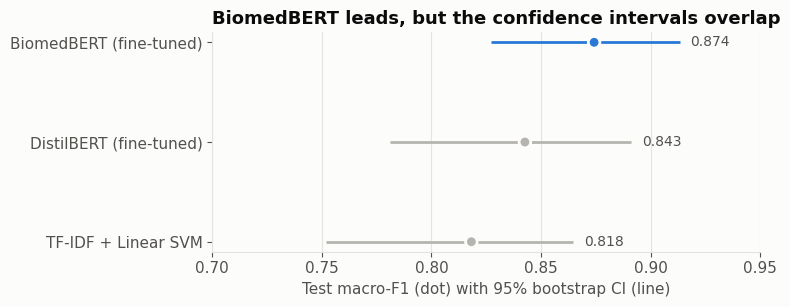

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(results))
colors = [BLUE if m == "biomedbert" else GRAY for m in results["model"]]

ax.hlines(y, results["ci_low"], results["ci_high"], color=colors, linewidth=2)
ax.scatter(results["macro_f1"], y, color=colors, s=70, zorder=3,
           edgecolor=SURFACE, linewidth=2)
for yi, (_, r) in zip(y, results.iterrows()):
    ax.text(r["ci_high"] + 0.005, yi, f"{r['macro_f1']:.3f}", va="center",
            color=INK2, fontsize=10)

ax.set_yticks(y, [NAMES[m] for m in results["model"]])
ax.set_xlim(0.70, 0.95)
ax.set_xlabel("Test macro-F1 (dot) with 95% bootstrap CI (line)")
ax.grid(axis="y", visible=False)
ax.set_title("BiomedBERT leads, but the confidence intervals overlap")
fig.tight_layout()
fig.savefig(DOCS / "model_comparison.png", dpi=150)
plt.show()

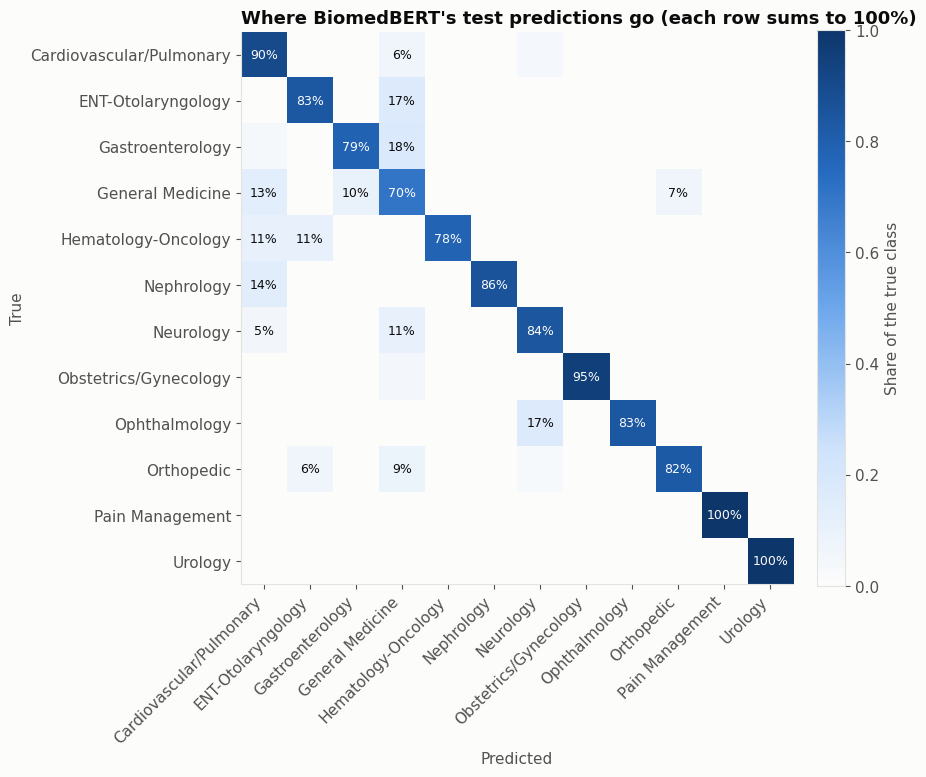

In [9]:
preds = pd.read_csv(REPORTS / "day6_test_predictions.csv")
labels = sorted(preds["true"].unique())
cm = confusion_matrix(preds["true"], preds["biomedbert"], labels=labels, normalize="true")

cmap = LinearSegmentedColormap.from_list(
    "blue_seq", [SURFACE, "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
short = [l.replace(" / ", "/").replace(" - ", "-") for l in labels]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), short, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), short)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color=SURFACE if cm[i, j] > 0.5 else INK)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Share of the true class")
ax.set_title("Where BiomedBERT's test predictions go (each row sums to 100%)")
fig.tight_layout()
fig.savefig(DOCS / "confusion_matrix.png", dpi=150)
plt.show()

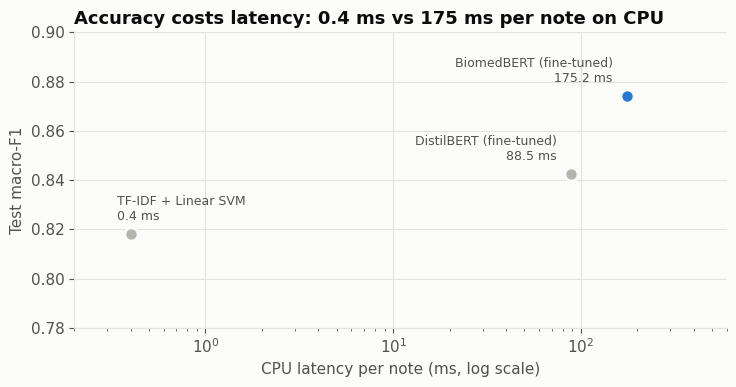

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for _, r in results.iterrows():
    color = BLUE if r["model"] == "biomedbert" else GRAY
    ax.scatter(r["cpu_ms"], r["macro_f1"], s=90, color=color, zorder=3,
               edgecolor=SURFACE, linewidth=2)
    ax.annotate(f"{NAMES[r['model']]}\n{r['cpu_ms']:.1f} ms", (r["cpu_ms"], r["macro_f1"]),
                textcoords="offset points", xytext=(-10, 10), ha="right" if r["cpu_ms"] > 50 else "left",
                color=INK2, fontsize=9)

ax.set_xscale("log")
ax.set_xlim(0.2, 600)
ax.set_ylim(0.78, 0.90)
ax.set_xlabel("CPU latency per note (ms, log scale)")
ax.set_ylabel("Test macro-F1")
ax.set_title("Accuracy costs latency: 0.4 ms vs 175 ms per note on CPU")
fig.tight_layout()
fig.savefig(DOCS / "accuracy_vs_latency.png", dpi=150)
plt.show()

In [14]:
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

val = pd.read_csv(ROOT / "data" / "processed" / "val.csv")
device = "cuda" if torch.cuda.is_available() else "cpu"
model_dir = ROOT / "models" / "biomedbert"
tokenizer = AutoTokenizer.from_pretrained(model_dir)
model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device).eval()

texts, batches = val["text"].tolist(), []
with torch.no_grad():
    for i in range(0, len(texts), 16):
        batch = tokenizer(texts[i:i + 16], truncation=True, max_length=512,
                          padding=True, return_tensors="pt").to(device)
        batches.append(torch.softmax(model(**batch).logits, dim=-1).cpu().numpy())
probs = np.vstack(batches)

conf = probs.max(axis=1)
pred = np.array([model.config.id2label[i] for i in probs.argmax(axis=1)])
correct = pred == val["label"].to_numpy()

thresholds = np.round(np.arange(0.30, 1.00, 0.01), 2)
coverage = np.array([(conf >= t).mean() for t in thresholds])
auto_acc = np.array([correct[conf >= t].mean() if (conf >= t).any() else np.nan
                     for t in thresholds])

table = pd.DataFrame({"threshold": thresholds, "coverage": coverage,
                      "auto_accuracy": auto_acc,
                      "sent_to_review": ((conf[:, None] < thresholds).sum(axis=0))})
print(f"Overall validation accuracy (no threshold): {correct.mean():.3f}")
table[table["threshold"].isin([0.5, 0.6, 0.7, 0.8, 0.9, 0.95])].round(3)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Overall validation accuracy (no threshold): 0.912


,threshold,coverage,auto_accuracy,sent_to_review
20,0.50,1.000,0.912,0
30,0.60,0.992,0.915,2
40,0.70,0.992,0.915,2
50,0.80,0.976,0.922,6
60,0.90,0.964,0.929,9
65,0.95,0.952,0.937,12


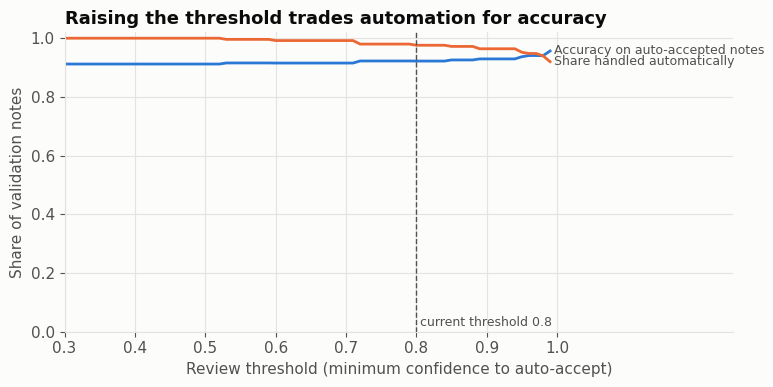

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, auto_acc, color=BLUE, linewidth=2)
ax.plot(thresholds, coverage, color=ORANGE, linewidth=2)
ax.text(thresholds[-1] + 0.005, auto_acc[-1], "Accuracy on auto-accepted notes",
        color=INK2, va="center", fontsize=9)
ax.text(thresholds[-1] + 0.005, coverage[-1], "Share handled automatically",
        color=INK2, va="center", fontsize=9)
ax.axvline(0.8, color=INK2, linewidth=1, linestyle="--")
ax.text(0.8, 0.02, " current threshold 0.8", color=INK2, fontsize=9, transform=ax.get_xaxis_transform())
ax.set_xlim(0.3, 1.25)
ax.set_xticks(np.arange(0.3, 1.01, 0.1))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Review threshold (minimum confidence to auto-accept)")
ax.set_ylabel("Share of validation notes")
ax.set_title("Raising the threshold trades automation for accuracy")
fig.tight_layout()
fig.savefig(DOCS / "review_threshold.png", dpi=150)
plt.show()